# 🏆 Notebook 04b · Evaluación y Selección de Modelos
---
**Proyecto:** Bogotá — Análisis Predictivo del Mercado Inmobiliario Urbano
**Fuente:** UAECD / IDECA · 2021–2026
**Autor:** Kevin Palacio Martinez

> ⚠️ **Reescrito el 2026-08-04.** La versión anterior de este notebook comparaba
> 10 modelos con `train_test_split` aleatorio y seleccionaba XGBoost con
> R²=0,8454 y MAE $308.368. Esas métricas eran **inválidas**: el dataset es un
> panel donde cada manzana aparece ~6 veces con features casi constantes, así
> que el split aleatorio dejaba filas hermanas de cada manzana en el train.
> El modelo no estimaba valor, **re-identificaba la manzana** — y lo hacía peor
> que un `groupby`. Los artefactos de esa iteración fueron eliminados.

---
## 🎯 Objetivo

Evaluar modelos bajo un protocolo que corresponda al **caso de uso real**:
estimar el valor de un año o de un predio que el modelo no ha visto.

## 🔑 Principio rector

> **Un modelo solo sirve si le gana a lo trivial bajo el mismo protocolo.**

Por eso cada protocolo se acompaña de su baseline: si el modelo no lo supera,
su R² no prueba que haya aprendido nada del mercado.

## 📋 Contenido

| Sección | Descripción |
|---|---|
| 1 | Carga del dataset y construcción de rezagos |
| 2 | Cuatro protocolos de evaluación + baselines triviales |
| 3 | Comparación visual |
| 4 | Análisis de errores del modelo vigente |
| 5 | Entrenamiento y exportación del v2 con metadatos honestos |

> La lógica vive en `avaluo/reevaluacion_modelo.py` y `avaluo/entrenar_modelo.py`.
> Este notebook la **presenta**; no la duplica. Así lo que se audita es un
> módulo con pruebas, no celdas sueltas con estado de kernel.

---
## ⚙️ Sección 1 · Carga y construcción de rezagos

> Se lee `data/processed/dataset_modelado.parquet` — el dataset de modelado sin
> las columnas de predicción del Random Forest descartado.
>
> **Rezagos**: lo único que se conoce *antes* del año que se quiere estimar.
> - `valor_manzana_t1` — valor de referencia de la manzana el año anterior
> - `var_loc_t1` — variación de la localidad el año anterior
>
> La `variacion_localidad` original se **descarta**: se derivaba de la mediana
> del propio target en el año en curso (fuga) y no existe ex ante — para estimar
> 2027 habría que conocer la variación de 2027.

In [1]:
import sys
sys.path.append('../avaluo')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# La lógica auditada vive en el paquete, no en el notebook.
from reevaluacion_modelo import (cargar, modelo, FEATURES_NB04B,
                                 FEATURES_LIMPIAS, TARGET)
from entrenar_modelo import FEATURES_V2

sns.set_theme(style="whitegrid", font_scale=1.1)
pd.set_option('display.float_format', '{:,.4f}'.format)
print("✓ Módulos de avaluo/ cargados")

✓ Módulos de avaluo/ cargados


In [2]:
df = cargar()

print(f"Dataset      : {len(df):,} filas")
print(f"Manzanas     : {df['cod_manzana'].nunique():,}")
print(f"Años         : {df['anio'].min()}–{df['anio'].max()}")

print(f"\n── Por qué el split aleatorio no sirve aquí ─────────────")
filas = df.groupby('cod_manzana').size().value_counts().sort_index()
print(f"  Manzanas con 6 apariciones : {filas.get(6, 0):,} de {df['cod_manzana'].nunique():,}")
intra = df.groupby('cod_manzana')[TARGET].std().mean()
total = df[TARGET].std()
print(f"  Desv. típica intra-manzana : ${intra:,.0f}")
print(f"  Desv. típica global        : ${total:,.0f}")
print(f"  Ratio intra/global         : {intra/total:.3f}")
print(f"  → El {(1-(intra/total)**2)*100:.0f}% de la varianza del target es ENTRE manzanas:")
print(f"    con split aleatorio el modelo puede memorizarla desde las filas hermanas.")

print(f"\n── Conjuntos de features ────────────────────────────────")
print(f"  NB04b original ({len(FEATURES_NB04B)}) : {FEATURES_NB04B}")
print(f"  Sin fuga       ({len(FEATURES_LIMPIAS)}) : {FEATURES_LIMPIAS}")
print(f"  v2 autorregr.  ({len(FEATURES_V2)}) : {FEATURES_V2}")

Dataset      : 252,700 filas
Manzanas     : 43,459
Años         : 2021–2026

── Por qué el split aleatorio no sirve aquí ─────────────
  Manzanas con 6 apariciones : 40,813 de 43,459
  Desv. típica intra-manzana : $312,019
  Desv. típica global        : $1,411,001
  Ratio intra/global         : 0.221
  → El 95% de la varianza del target es ENTRE manzanas:
    con split aleatorio el modelo puede memorizarla desde las filas hermanas.

── Conjuntos de features ────────────────────────────────
  NB04b original (9) : ['anio_norm', 'localidad_enc', 'territorio_enc', 'variacion_localidad', 'dist_tm_m', 'dist_metro_m', 'dist_sitp_m', 'estrato', 'indice_inseguridad']
  Sin fuga       (8) : ['anio_norm', 'localidad_enc', 'territorio_enc', 'dist_tm_m', 'dist_metro_m', 'dist_sitp_m', 'estrato', 'indice_inseguridad']
  v2 autorregr.  (10) : ['anio_norm', 'localidad_enc', 'territorio_enc', 'dist_tm_m', 'dist_metro_m', 'dist_sitp_m', 'estrato', 'indice_inseguridad', 'valor_manzana_t1', 'var_loc_t1']


---
## 🤖 Sección 2 · Cuatro protocolos + baselines triviales

> | Protocolo | Qué mide | Baseline que lo acompaña |
> |---|---|---|
> | **A · aleatorio** | Nada útil: el del NB04b original | Media de la propia manzana |
> | **B · por manzana** | Generalización a un **predio nuevo** | — |
> | **C · temporal** | Estimar un **año no visto** — el caso de uso real | Repetir el valor del año anterior |
>
> El protocolo **C** es el que debe reportarse en un avalúo: es el único que
> reproduce las condiciones en que el modelo se usará de verdad.

In [3]:
# Ejecuta los cuatro protocolos definidos en avaluo/reevaluacion_modelo.py
# (se corre como módulo para que el notebook no duplique la lógica auditada)
import subprocess
salida = subprocess.run([sys.executable, 'reevaluacion_modelo.py'],
                        cwd='../avaluo', capture_output=True, text=True,
                        encoding='utf-8')
print(salida.stdout[-2000:] if salida.stdout else salida.stderr[-2000:])

df_resultados = pd.read_csv('../data/processed/reevaluacion_modelo.csv')
display(df_resultados)

Dataset: 252,700 filas · 43,459 manzanas · años 2021–2026

════════════════════════════════════════════════════════════════════════════════════════════

── A · aleatorio (el del NB04b) ──────────────────────────────────────────────────────────
  BASELINE media de la propia manzana        R²= 0.8942   MAE=$     299,123   n= 50,540  ←
  XGBoost (9 features NB04b)                 R²= 0.8588   MAE=$     304,626   n= 50,540   

── B · por manzana (predio nuevo) ────────────────────────────────────────────────────────
  XGBoost (sin variacion_localidad)          R²= 0.8112   MAE=$     325,449   n= 50,557   
  XGBoost (9 features NB04b)                 R²= 0.8090   MAE=$     327,873   n= 50,557   

── C · temporal (≤2025 → 2026) ───────────────────────────────────────────────────────────
  XGBoost AUTORREGRESIVO (+valor t-1)        R²= 0.9168   MAE=$     259,830   n= 41,519   
  BASELINE valor del año anterior            R²= 0.8965   MAE=$     315,489   n= 41,519  ←
  XGBoost (sin variacion_l

,modelo,protocolo,R2,MAE,n_test
0,XGBoost (9 features NB04b),A · aleatorio (el del NB04b),0.8588,"304,626.0000",50540
1,BASELINE media de la propia manzana,A · aleatorio (el del NB04b),0.8942,"299,123.0000",50540
2,XGBoost (9 features NB04b),B · por manzana (predio nuevo),0.8090,"327,873.0000",50557
3,XGBoost (sin variacion_localidad),B · por manzana (predio nuevo),0.8112,"325,449.0000",50557
4,XGBoost (9 features NB04b),C · temporal (≤2025 → 2026),0.7198,"553,984.0000",41536
5,XGBoost (sin variacion_localidad),C · temporal (≤2025 → 2026),0.7964,"473,651.0000",41536
6,BASELINE valor del año anterior,C · temporal (≤2025 → 2026),0.8965,"315,489.0000",41519
7,XGBoost AUTORREGRESIVO (+valor t-1),C · temporal (≤2025 → 2026),0.9168,"259,830.0000",41519


---
## 📊 Sección 3 · Comparación visual

> Rojo = baseline trivial · Verde = modelo vigente (autorregresivo).
> Donde el rojo gana al azul, el modelo no aporta nada.

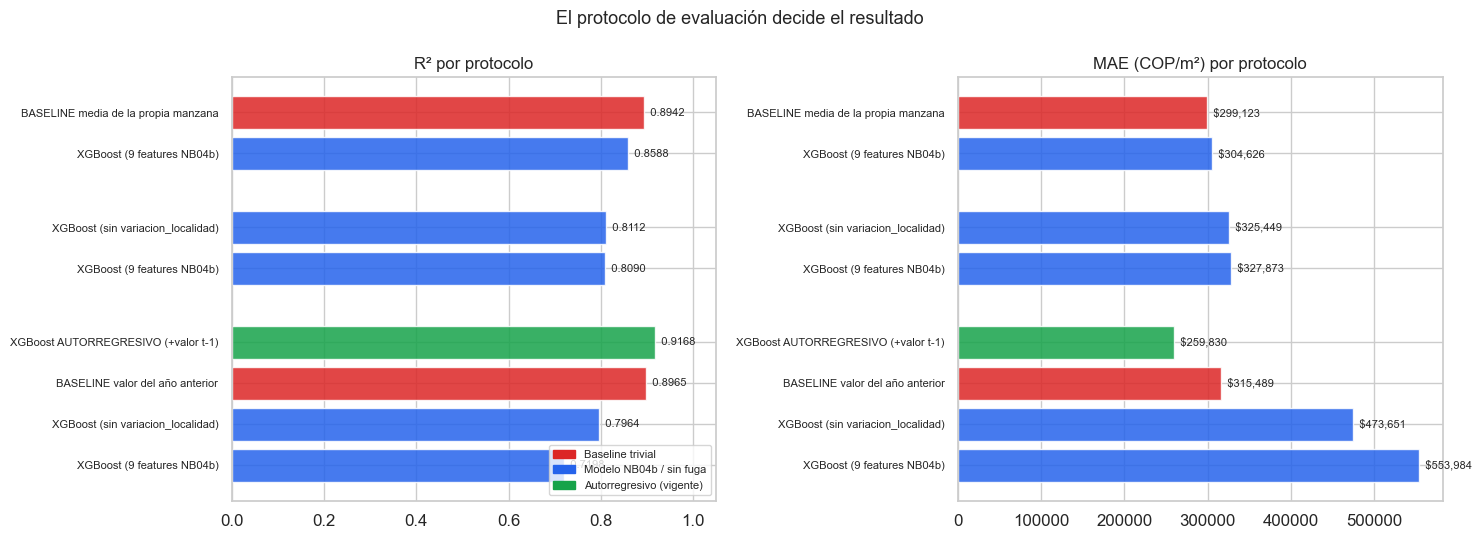

✓ Gráfico guardado en reports/figures/26_reevaluacion_protocolos.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
protocolos = df_resultados['protocolo'].unique()

for ax, met, tit in zip(axes, ['R2', 'MAE'],
                        ['R² por protocolo', 'MAE (COP/m²) por protocolo']):
    y, ticks, labels = 0, [], []
    for p in protocolos:
        sub = df_resultados[df_resultados.protocolo == p].sort_values(
            met, ascending=(met == 'MAE'))
        for _, r in sub.iterrows():
            es_base = r['modelo'].startswith('BASELINE')
            color = ('#DC2626' if es_base
                     else '#16A34A' if 'AUTORREGRESIVO' in r['modelo']
                     else '#2563EB')
            ax.barh(y, r[met], color=color, alpha=0.85)
            etiqueta = f"  {r[met]:,.4f}" if met == 'R2' else f"  ${r[met]:,.0f}"
            ax.text(r[met], y, etiqueta, va='center', fontsize=8)
            ticks.append(y); labels.append(r['modelo'][:38]); y += 1
        y += 0.8
    ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(tit, fontsize=12); ax.invert_yaxis()
    if met == 'R2':
        ax.set_xlim(0, 1.05)

from matplotlib.patches import Patch
axes[0].legend(handles=[
    Patch(color='#DC2626', label='Baseline trivial'),
    Patch(color='#2563EB', label='Modelo NB04b / sin fuga'),
    Patch(color='#16A34A', label='Autorregresivo (vigente)')],
    loc='lower right', fontsize=8)

fig.suptitle('El protocolo de evaluación decide el resultado', fontsize=13)
plt.tight_layout()
plt.savefig('../reports/figures/26_reevaluacion_protocolos.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✓ Gráfico guardado en reports/figures/26_reevaluacion_protocolos.png")

---
## 🔍 Sección 4 · Análisis de errores del modelo vigente

> Errores del **v2 autorregresivo** bajo el holdout temporal (≤2025 → 2026),
> que es el único escenario en que el error medido corresponde al error real
> de uso. El análisis de la versión anterior de este notebook se hacía sobre
> el test aleatorio y por eso subestimaba el error.

── Error del v2 · holdout temporal (n=41,519) ──────
  MAE            : $259,830 COP/m²
  Error mediano  : 6.4%
  P90 del error  : 26.3%

── Error mediano por localidad ──────────────────────────


,localidad,error_mediano,error_p90
0,CHAPINERO,14.1600,56.1300
1,SANTA FE,11.6400,43.8000
2,KENNEDY,10.3600,27.5300
3,RAFAEL URIBE URIBE,8.2200,31.7400
4,TEUSAQUILLO,7.2800,19.2300
5,CIUDAD BOLIVAR,7.2200,38.9500
6,SUBA,6.6800,21.0500
7,SAN CRISTOBAL,6.6200,10.5000
8,USAQUEN,6.3300,26.9700
9,PUENTE ARANDA,6.0700,18.8900


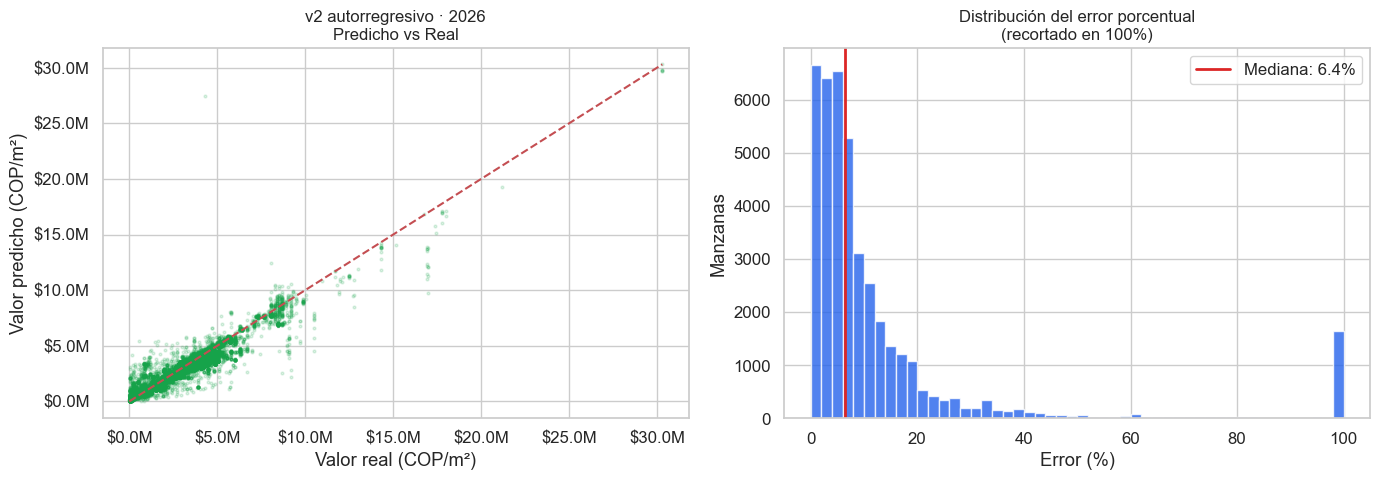

✓ Gráfico guardado en reports/figures/27_errores_modelo_v2.png


In [5]:
d = df.dropna(subset=FEATURES_V2)
tr, te = d['anio'] <= 2025, d['anio'] == 2026

m = modelo()
m.fit(d[tr][FEATURES_V2], d[tr][TARGET])
pred = m.predict(d[te][FEATURES_V2])

err = d[te][['cod_manzana', 'localidad', TARGET]].copy()
err['valor_predicho'] = pred
err['error_abs'] = (err[TARGET] - err['valor_predicho']).abs()
err['error_pct'] = (err['error_abs'] / err[TARGET] * 100).round(2)

print(f"── Error del v2 · holdout temporal (n={len(err):,}) ──────")
print(f"  MAE            : ${err['error_abs'].mean():,.0f} COP/m²")
print(f"  Error mediano  : {err['error_pct'].median():.1f}%")
print(f"  P90 del error  : {err['error_pct'].quantile(0.90):.1f}%")

error_localidad = (err.groupby('localidad')['error_pct']
                   .agg(error_mediano='median', error_p90=lambda s: s.quantile(0.9))
                   .round(2).sort_values('error_mediano', ascending=False)
                   .reset_index())
print(f"\n── Error mediano por localidad ──────────────────────────")
display(error_localidad)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(err[TARGET], err['valor_predicho'], alpha=0.15, s=4, color='#16A34A')
lim = max(err[TARGET].max(), err['valor_predicho'].max())
axes[0].plot([0, lim], [0, lim], 'r--', linewidth=1.5)
axes[0].set_title('v2 autorregresivo · 2026\nPredicho vs Real', fontsize=12)
axes[0].set_xlabel('Valor real (COP/m²)'); axes[0].set_ylabel('Valor predicho (COP/m²)')
for eje in (axes[0].xaxis, axes[0].yaxis):
    eje.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))

axes[1].hist(err['error_pct'].clip(0, 100), bins=50, color='#2563EB',
             alpha=0.8, edgecolor='white')
axes[1].axvline(err['error_pct'].median(), color='#DC2626', linewidth=2,
                label=f"Mediana: {err['error_pct'].median():.1f}%")
axes[1].set_title('Distribución del error porcentual\n(recortado en 100%)', fontsize=12)
axes[1].set_xlabel('Error (%)'); axes[1].set_ylabel('Manzanas'); axes[1].legend()

plt.tight_layout()
plt.savefig('../reports/figures/27_errores_modelo_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Gráfico guardado en reports/figures/27_errores_modelo_v2.png")

---
## 💾 Sección 5 · Entrenamiento y exportación del v2

> Se exportan **dos cosas distintas**, y confundirlas es la trampa clásica:
>
> - El modelo que se **evalúa** se entrena solo con ≤2025 y se mide contra 2026.
>   De ahí salen las métricas que se publican.
> - El modelo que se **exporta** se reentrena con todo (≤2026) para estimar 2027.
>   No se puede medir todavía: no existe el dato real de 2027.
>
> Los metadatos declaran protocolo, baseline, ganancia sobre lo trivial,
> limitaciones y fecha de corte de los insumos.

In [6]:
# El entrenamiento y la exportación viven en avaluo/entrenar_modelo.py:
# el notebook no reimplementa nada, solo lo invoca y muestra el resultado.
salida = subprocess.run([sys.executable, 'entrenar_modelo.py'],
                        cwd='../avaluo', capture_output=True, text=True,
                        encoding='utf-8')
print(salida.stdout if salida.stdout else salida.stderr)

import json
meta = json.loads(open('../models/modelo_v2_metadata.json', encoding='utf-8').read())

print("\n── Metadatos del modelo exportado ───────────────────────")
print(f"  Modelo    : {meta['modelo']} {meta['version']}")
print(f"  Protocolo : {meta['protocolo_evaluacion']['tipo']} — "
      f"train {meta['protocolo_evaluacion']['train']}, "
      f"test {meta['protocolo_evaluacion']['test']}")
print(f"  R²        : {meta['metricas']['r2']}")
print(f"  MAE       : ${meta['metricas']['mae_cop_m2']:,} COP/m²")
print(f"  Baseline  : MAE ${meta['baseline_mismo_protocolo']['mae_cop_m2']:,} "
      f"→ ganancia ${meta['baseline_mismo_protocolo']['ganancia_mae_cop_m2']:,}")
print(f"\n  Limitaciones declaradas:")
for lim in meta['limitaciones']:
    print(f"    · {lim}")

── Evaluación · holdout temporal (≤2025 → 2026) ──────────
  n_train 124,742 · n_test 41,519

  Modelo v2 autorregresivo   R²=0.9168  MAE=$259,830  RMSE=$459,899
  BASELINE valor año previo  R²=0.8965  MAE=$315,489  RMSE=$512,944

  → SUPERA al baseline: +55,659 COP/m² de MAE (+17.6%)

  Importancia de variables:
    valor_manzana_t1       0.8955
    dist_metro_m           0.0244
    var_loc_t1             0.0178
    anio_norm              0.0139
    estrato                0.0103
    dist_tm_m              0.0100
    indice_inseguridad     0.0096
    dist_sitp_m            0.0084
    localidad_enc          0.0062
    territorio_enc         0.0038

✓ Modelo   → xgboost_autorregresivo_v2.joblib (1299 KB)
✓ Metadatos→ modelo_v2_metadata.json
✓ Registrado en sustento.db (ambito='modelo')


── Metadatos del modelo exportado ───────────────────────
  Modelo    : XGBoost autorregresivo v2
  Protocolo : holdout temporal — train años ≤ 2025, test año 2026
  R²        : 0.9168
  MAE       : $259

---
## 📚 Fuentes y referencias

### Metodología de evaluación

| Tema | Referencia |
|---|---|
| Evaluación con origen temporal | Hyndman, R.J. & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3ª ed., cap. 5.8-5.10 |
| Fuga de información en panel | Kaufman, S. et al. (2012). *Leakage in Data Mining*. ACM TKDD 6(4) |
| Validación con grupos | Roberts, D.R. et al. (2017). *Cross-validation strategies for data with spatial, temporal, phylogenetic or hierarchical structure*. Ecography 40(8) |

### Modelo

| Modelo | Referencia |
|---|---|
| XGBoost | Chen, T. & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. KDD |

### Sustento normativo del uso

> El resultado de este modelo **no es un avalúo**. Los métodos valuatorios
> admitidos están en el **Decreto 1170 de 2015 art. 2.2.2.6.3** (que compila el
> **Decreto 1420 de 1998 art. 25**): comparación de mercado, capitalización de
> rentas, costo de reposición y residual. Consultables con:
> `python avaluo/sustento_pipeline.py --buscar "comparacion mercado"`

### Librerías

`scikit-learn` · `xgboost` · `pandas` · `joblib`

---
## ✅ Cierre del Notebook 04b · Evaluación y Selección

### Resumen ejecutivo

Reevaluación del modelo bajo cuatro protocolos, con baselines triviales como
piso de comparación obligatorio.

### 📊 Hallazgos

| # | Hallazgo |
|---|---|
| 1 | Bajo el protocolo original (split aleatorio), **el baseline de la media de la propia manzana supera al modelo** (R² 0,8942 vs 0,8588): el R²=0,8454 nunca fue evidencia de aprendizaje |
| 2 | `variacion_localidad` no solo era fuga: **quitarla mejora** la predicción temporal (R² 0,7198 → 0,7964) |
| 3 | El **v2 autorregresivo** es la única configuración que gana al baseline ingenuo: R²=0,9168 · MAE $259.830 vs $315.489 |
| 4 | El 90% de la importancia del v2 está en `valor_manzana_t1`: es "el valor del año pasado, ajustado" — y ese ajuste vale un 17,6% menos de error |

### 🏆 Modelo vigente

`models/xgboost_autorregresivo_v2.joblib` — metadatos en `models/modelo_v2_metadata.json`

### ⚠️ Qué NO hace este modelo

- No estima el valor comercial de un **predio**: estima el valor de referencia
  de **terreno por manzana**
- No sustituye el método de comparación de mercado (D.1170/2015)
- Con ~10% de error típico sirve para acotar un **rango**, no para fijar un valor

### 💾 Archivos generados

| Archivo | Descripción |
|---|---|
| `models/xgboost_autorregresivo_v2.joblib` | Modelo de producción |
| `models/modelo_v2_metadata.json` | Protocolo, métricas, baseline y limitaciones |
| `data/processed/reevaluacion_modelo.csv` | Los cuatro protocolos |
| `reports/figures/26_reevaluacion_protocolos.png` | Comparación visual |
| `reports/figures/27_errores_modelo_v2.png` | Errores del v2 |

---
*Proyecto: Bogotá — Análisis Predictivo del Mercado Inmobiliario Urbano*
*Reescrito 2026-08-04 · lógica en `avaluo/` · sustento en `docs/sustento.db`*